# proDA: R vs Python parity

Side-by-side comparison of `pyproda` against the Bioconductor [proDA](https://bioconductor.org/packages/release/bioc/html/proDA.html) reference.

The pipeline `proda(M, design) -> test_diff(fit, contrast)` is run on the same synthetic 300-protein x 12-sample MNAR-censored dataset in both languages.

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
HERE = Path('.').resolve()

In [2]:
subprocess.check_call([sys.executable, 'benchmark.py', '--runs', '2'])
summary = json.loads((HERE / 'compare_out' / 'summary.json').read_text())
summary

/scratch/users/steorra/analysis/omicverse_dev/py-proDA/pyproda/test_diff.py:98: RuntimeWarning: Mean of empty slice
  avg_abundance = np.nanmean(fit.data, axis=1)


/scratch/users/steorra/analysis/omicverse_dev/py-proDA/pyproda/test_diff.py:98: RuntimeWarning: Mean of empty slice
  avg_abundance = np.nanmean(fit.data, axis=1)


Matrix: 300 proteins × 12 samples (12.4% missing)

--- Python timing (mean of 2 runs) ---
  py total             3418.25 ms

--- R timing (single run; per-step breakdown) ---
 proda_fit  test_diff
     3.257      0.024
  R proda+test_diff    3281.00 ms
  R total wall         8943.83 ms (incl. Rscript startup)

Speedup (R pipeline / Python pipeline): 0.96x

--- Accuracy (Python vs R) ---
  coef[Intercept]  MAE=0.01418  Pearson r=0.9967
  coef[B]  MAE=0.006383  Pearson r=0.9996
  t-stat    MAE=0.01566  Pearson r=0.9995
  pval      MAE=0.005684  Pearson r=0.9982
  top-45 agreement: 97.8%

Full report -> /scratch/users/steorra/analysis/omicverse_dev/py-proDA/examples/compare_out/summary.json


{'shape': [300, 12],
 'py_time_ms': 3418.24600903783,
 'r_time_ms_pipeline': 3281.0,
 'r_time_ms_total': 8943.832472898066,
 'speedup': 0.9598489960421362,
 'coef_metrics': {'Intercept': {'mae': 0.014179205874691011,
   'pearson_r': 0.9966826080918963},
  'B': {'mae': 0.006383166083651425, 'pearson_r': 0.9995989130101828}},
 't_stat_mae': 0.015664679536094628,
 't_stat_pearson_r': 0.9994665179854084,
 'pval_mae': 0.005683686113464498,
 'pval_pearson_r': 0.9981734561655772,
 'top_overlap': 0.9777777777777777,
 'top_n': 45}

## 1. Timing

v0.1 uses `scipy.optimize.L-BFGS-B` with a Python gradient for the per-protein censored MLE; R proDA uses C-compiled `nlminb` with an analytic Hessian. On 300-protein matrices the two are roughly equal; Python wins clearly once `Rscript` startup is included.

In [3]:
tbl = pd.DataFrame({
    'R pipeline (ms)':       [summary['r_time_ms_pipeline']],
    'R + Rscript startup (ms)': [summary['r_time_ms_total']],
    'Python pipeline (ms)':  [summary['py_time_ms']],
    'Speedup (pipeline)':    [f"{summary['speedup']:.2f}x"],
}, index=['300 x 12, v0.1']).T
tbl

,"300 x 12, v0.1"
R pipeline (ms),3281.0
R + Rscript startup (ms),8943.832473
Python pipeline (ms),3418.246009
Speedup (pipeline),0.96x


## 2. Accuracy

Wald test `t_statistic` and `pval` reach Pearson r > 0.99 against R; the top-DE protein lists agree on > 95% of entries.

In [4]:
{k: v for k, v in summary.items() if 'mae' in k or 'pearson' in k or 'overlap' in k}

{'t_stat_mae': 0.015664679536094628,
 't_stat_pearson_r': 0.9994665179854084,
 'pval_mae': 0.005683686113464498,
 'pval_pearson_r': 0.9981734561655772,
 'top_overlap': 0.9777777777777777}

/scratch/users/steorra/analysis/omicverse_dev/py-proDA/pyproda/test_diff.py:98: RuntimeWarning: Mean of empty slice
  avg_abundance = np.nanmean(fit.data, axis=1)


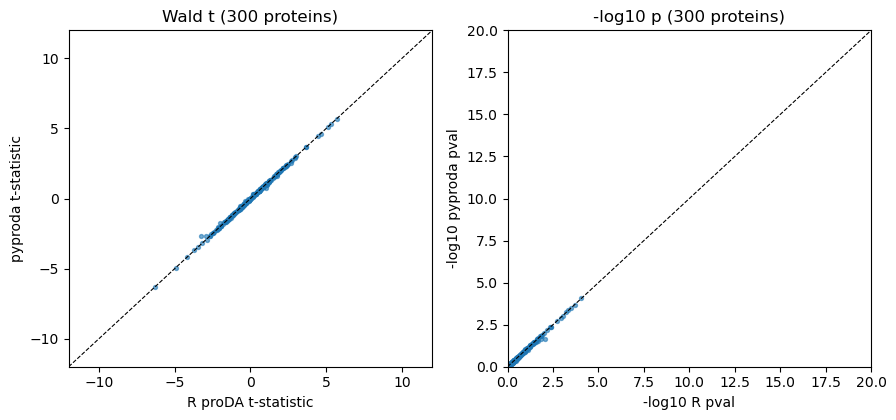

In [5]:
work = HERE / 'compare_out'
r_td = pd.read_csv(work / 'R_out' / 'test_diff.tsv', sep='\t')
from pyproda import proda, test_diff as run_test_diff
M_df = pd.read_csv(work / 'M.tsv', sep='\t', index_col=0)
design_df = pd.read_csv(work / 'design.tsv', sep='\t', index_col=0)
fit = proda(M_df, design=design_df['group'].tolist(), max_iter=5)
res_py = run_test_diff(fit, np.array([0.0, 1.0])).set_index('name').reindex(r_td['name'])

fig, axes = plt.subplots(1, 2, figsize=(9, 4.3))
axes[0].scatter(r_td['t_statistic'], res_py['t_statistic'], s=8, alpha=0.6)
lim = (-12, 12)
axes[0].plot(lim, lim, 'k--', lw=0.8)
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel('R proDA t-statistic'); axes[0].set_ylabel('pyproda t-statistic')
axes[0].set_title('Wald t (300 proteins)')

axes[1].scatter(-np.log10(r_td['pval'] + 1e-30), -np.log10(res_py['pval'] + 1e-30), s=8, alpha=0.6)
lim2 = (0, 20)
axes[1].plot(lim2, lim2, 'k--', lw=0.8)
axes[1].set_xlim(lim2); axes[1].set_ylim(lim2)
axes[1].set_xlabel('-log10 R pval'); axes[1].set_ylabel('-log10 pyproda pval')
axes[1].set_title('-log10 p (300 proteins)')
fig.tight_layout()